# Life Expectancy and GDP: An Empirical Investigation (2000–2015)

## Introduction
This project investigates the relationship between the economic output of nations (Gross Domestic Product) and the life expectancy of their citizens at birth. Using observational data spanning from **2000 to 2015** across six diverse countries, we perform exploratory data analysis, evaluate national growth trajectories, and test both linear and non-linear economic models (including the **Preston Curve**).

### Core Research Questions
1. **Longitudinal Trends:** Has life expectancy increased over time in the six nations?
2. **Economic Growth:** Has GDP increased over time in all six nations?
3. **Correlation:** Is there a statistically significant correlation between GDP and life expectancy within individual nations vs. across nations?
4. **Distributions:** What is the average and distribution of life expectancy and GDP across the dataset?
5. **Economic Theory (The Preston Curve):** Does the relationship between wealth and longevity follow a diminishing returns curve?

### Data Sources
* **GDP:** [World Bank National Accounts Data](https://data.worldbank.org/indicator/NY.GDP.MKTP.CD) and OECD National Accounts data files (in current U.S. Dollars).
* **Life Expectancy:** [World Health Organization (WHO) Global Health Observatory](http://apps.who.int/gho/data/node.main.688) (Life expectancy at birth in years).


## 1. Environment Setup & Data Ingestion
We begin by importing modern Python data science libraries (`pandas`, `numpy`, `matplotlib`, and `seaborn`) and setting up publication-grade visualization defaults.


In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns

# Visual configuration
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "figure.titlesize": 13,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
})

# Load dataset
df = pd.read_csv("all_data.csv")
print(df.head(10).to_string(index=False))


Country  Year  Life expectancy at birth (years)          GDP
  Chile  2000                              77.3 7.786093e+10
  Chile  2001                              77.3 7.097992e+10
  Chile  2002                              77.8 6.973681e+10
  Chile  2003                              77.9 7.564346e+10
  Chile  2004                              78.0 9.921039e+10
  Chile  2005                              78.4 1.229650e+11
  Chile  2006                              78.9 1.547880e+11
  Chile  2007                              78.9 1.736060e+11
  Chile  2008                              79.6 1.796380e+11
  Chile  2009                              79.3 1.723890e+11


## 2. Initial Data Inspection
Let's inspect the dataset schema, data types, distinct countries, and the temporal span covered.


In [2]:
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Data Types & Null Counts:")
print(df.info())
print("\nRepresented Nations:")
for c in df["Country"].unique():
    print(f" - {c}")
print(f"\nYear Range: {df['Year'].min()} – {df['Year'].max()} ({df['Year'].nunique()} consecutive years)")


Dataset Shape: 96 rows, 4 columns

Data Types & Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country                           96 non-null     str    
 1   Year                              96 non-null     int64  
 2   Life expectancy at birth (years)  96 non-null     float64
 3   GDP                               96 non-null     float64
dtypes: float64(2), int64(1), str(1)
memory usage: 3.1 KB
None

Represented Nations:
 - Chile
 - China
 - Germany
 - Mexico
 - United States of America
 - Zimbabwe

Year Range: 2000 – 2015 (16 consecutive years)


The dataset contains 96 complete observations with zero missing values across six nations:
* **Chile** (South America)
* **China** (East Asia)
* **Germany** (Western Europe)
* **Mexico** (North America)
* **United States of America** (North America)
* **Zimbabwe** (Southern Africa)

Each nation has exactly 16 annual observations (2000–2015).


## 3. Data Cleaning & Feature Engineering
To make analysis and visualization intuitive:
1. Rename `Life expectancy at birth (years)` to a concise variable name `LEABY`.
2. Convert `GDP` into Trillions of USD (`GDP_Trillions`) and Billions of USD (`GDP_Billions`) to eliminate unwieldy scientific notation.
3. Create a log-transformed GDP variable (`log_GDP`) for economic modeling.
4. Add a shortened country label (`USA`) for clearer chart legends.


In [3]:
# Rename target column
df = df.rename(columns={"Life expectancy at birth (years)": "LEABY"})

# Feature engineering
df["GDP_Trillions"] = df["GDP"] / 1e12
df["GDP_Billions"] = df["GDP"] / 1e9
df["log_GDP"] = np.log10(df["GDP"])
df["Country_Short"] = df["Country"].replace({"United States of America": "USA"})

print(df[["Country_Short", "Year", "LEABY", "GDP_Trillions", "log_GDP"]].head().to_string(index=False))


Country_Short  Year  LEABY  GDP_Trillions   log_GDP
        Chile  2000   77.3       0.077861 10.891320
        Chile  2001   77.3       0.070980 10.851136
        Chile  2002   77.8       0.069737 10.843462
        Chile  2003   77.9       0.075643 10.878771
        Chile  2004   78.0       0.099210 10.996557


## 4. Univariate Distributions
Before comparing countries, let's examine the overall distributions of `GDP` and `LEABY`.


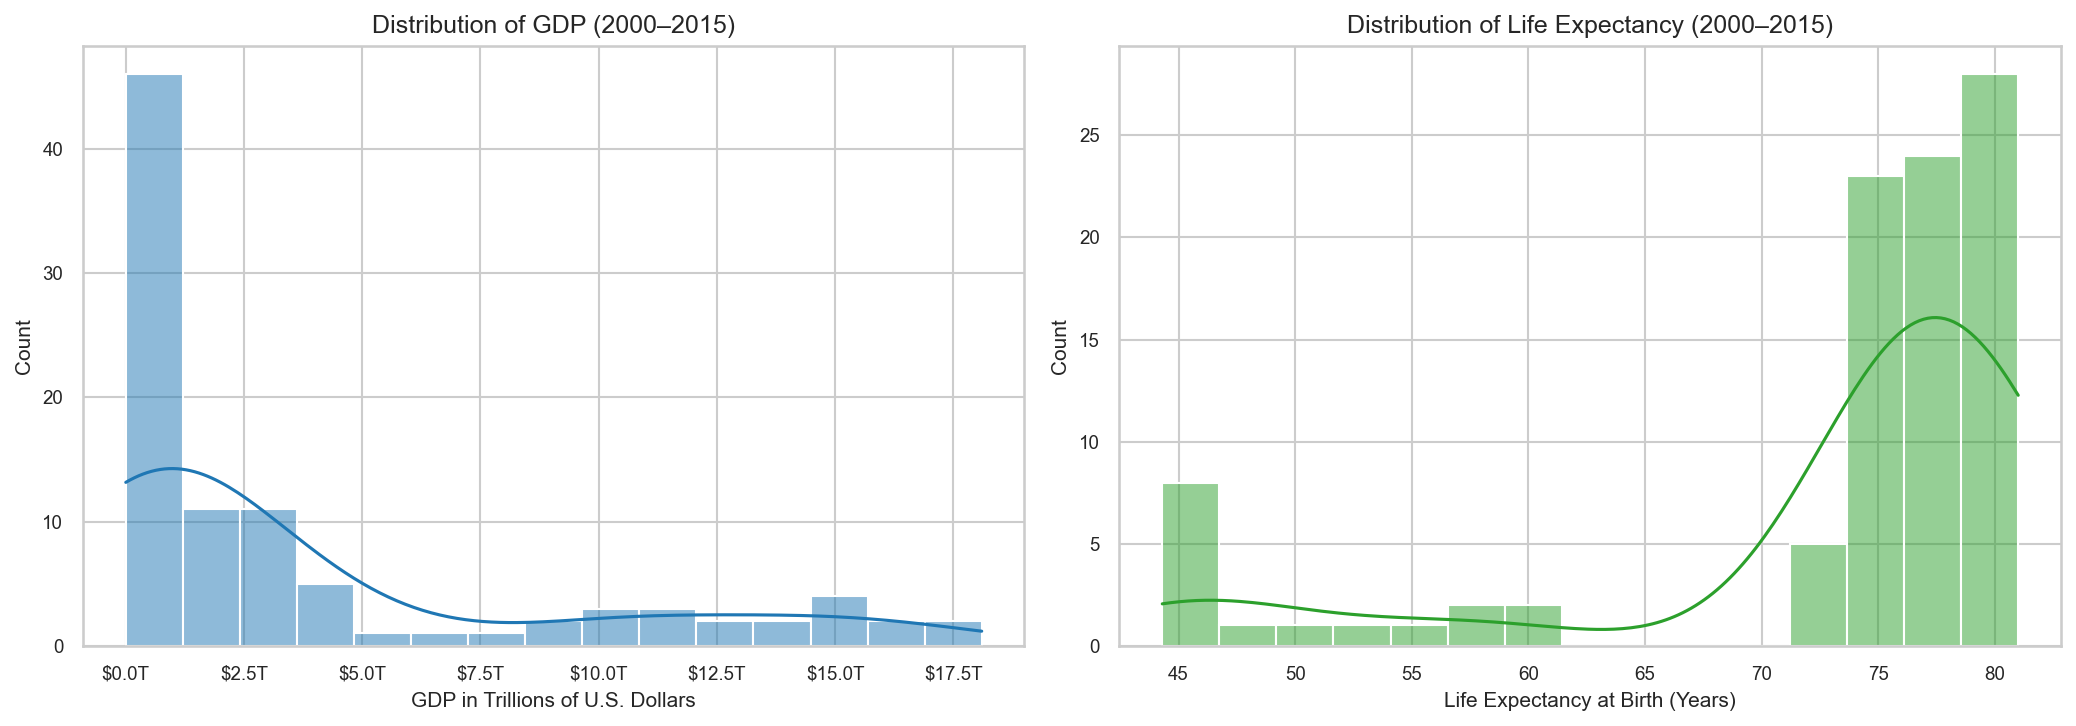

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# GDP Distribution
sns.histplot(df["GDP_Trillions"], kde=True, ax=axes[0], color="#1f77b4", bins=15)
axes[0].set_title("Distribution of GDP (2000–2015)")
axes[0].set_xlabel("GDP in Trillions of U.S. Dollars")
axes[0].set_ylabel("Count")
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.1f}T"))

# Life Expectancy Distribution
sns.histplot(df["LEABY"], kde=True, ax=axes[1], color="#2ca02c", bins=15)
axes[1].set_title("Distribution of Life Expectancy (2000–2015)")
axes[1].set_xlabel("Life Expectancy at Birth (Years)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


### Observations on Distributions
* **GDP (Right-Skewed):** The majority of observations are clustered under $2 Trillion (Chile, Mexico, Zimbabwe, Germany, and early China). A few observations stretch out toward $18 Trillion (the United States and later China).
* **Life Expectancy (Left-Skewed):** Most observations cluster between 74 and 81 years (representing Germany, Chile, USA, Mexico, and recent China). Observations below 65 years correspond entirely to Zimbabwe during its early-to-mid 2000s health crisis.


## 5. Country-Level Averages & Comparative Baseline
Let's group the dataset by nation to compute the mean GDP and life expectancy across the 16-year period.


In [5]:
dfMeans = df.groupby(["Country", "Country_Short"])[["LEABY", "GDP_Trillions", "GDP_Billions"]].mean().reset_index()
means_table = dfMeans.sort_values(by="LEABY", ascending=False)[["Country_Short", "LEABY", "GDP_Trillions", "GDP_Billions"]]
print(means_table.to_string(index=False, formatters={
    "LEABY": "{:.1f} yrs".format,
    "GDP_Trillions": "${:.2f}T".format,
    "GDP_Billions": "${:,.1f}B".format,
}))


Country_Short    LEABY GDP_Trillions GDP_Billions
      Germany 79.7 yrs        $3.09T    $3,094.8B
        Chile 78.9 yrs        $0.17T      $169.8B
          USA 78.1 yrs       $14.07T   $14,075.0B
       Mexico 75.7 yrs        $0.98T      $976.7B
        China 74.3 yrs        $4.96T    $4,957.7B
     Zimbabwe 50.1 yrs        $0.01T        $9.1B


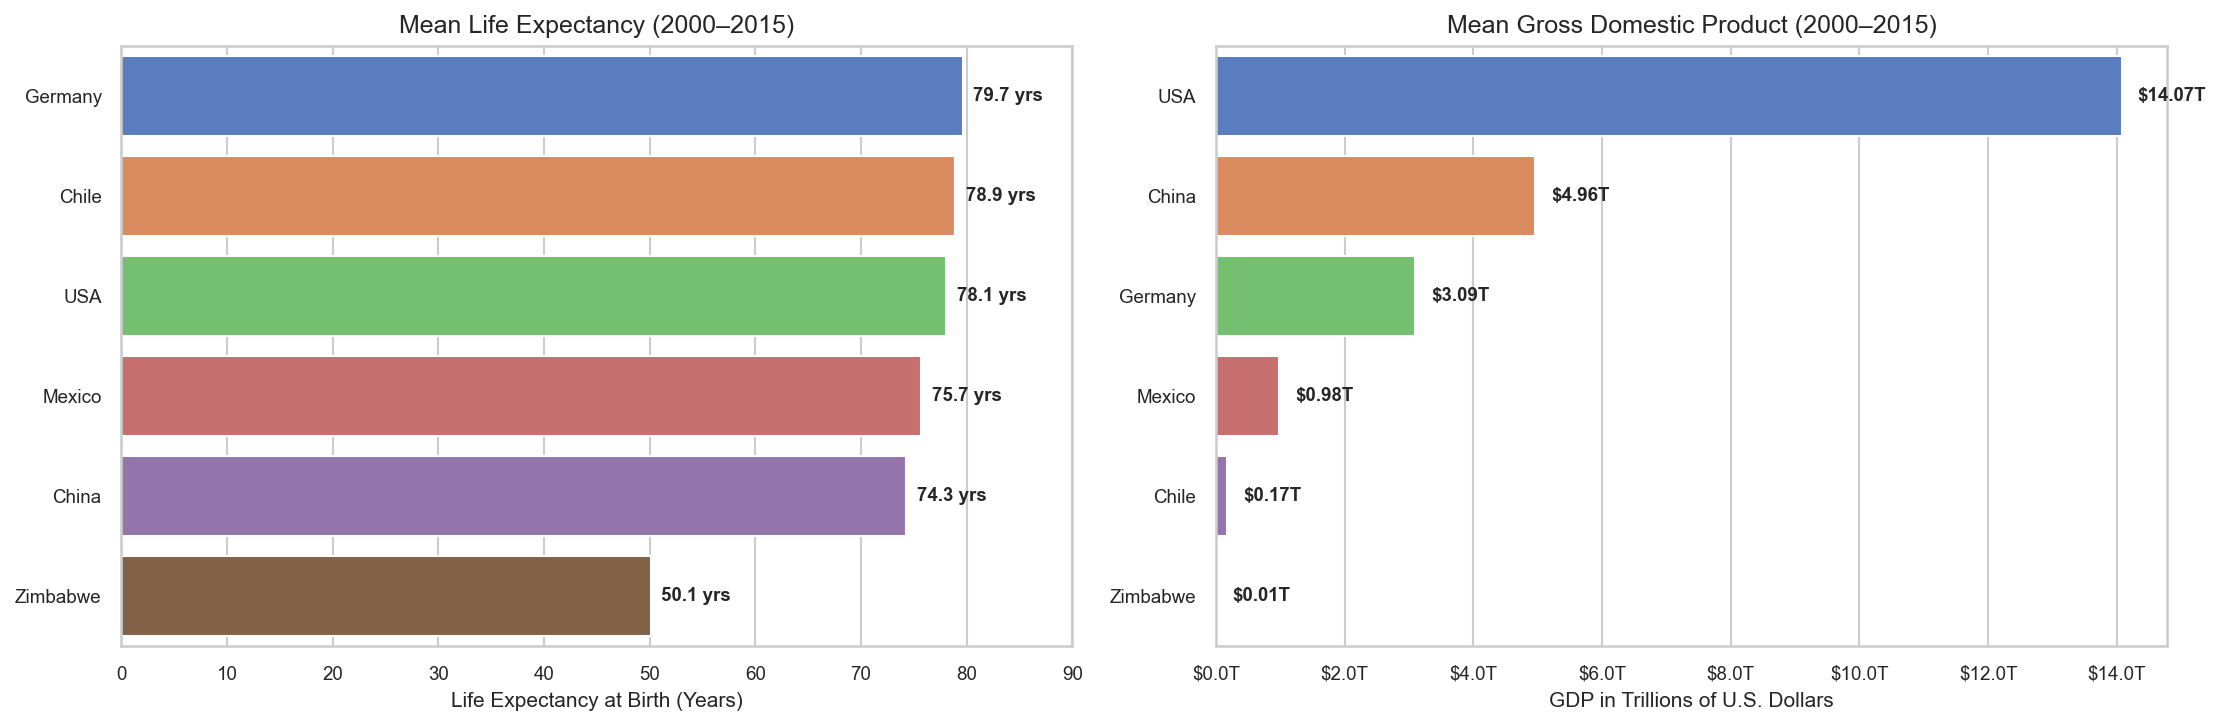

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
palette = sns.color_palette("muted", n_colors=len(dfMeans))

# Life Expectancy Bar Plot
sorted_le = dfMeans.sort_values(by="LEABY", ascending=False)
sns.barplot(data=sorted_le, x="LEABY", y="Country_Short", hue="Country_Short", palette=palette, legend=False, ax=axes[0])
axes[0].set_title("Mean Life Expectancy (2000–2015)")
axes[0].set_xlabel("Life Expectancy at Birth (Years)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 90)
for p in axes[0].patches:
    w = p.get_width()
    axes[0].annotate(f"{w:.1f} yrs", (w + 1.0, p.get_y() + p.get_height() / 2), va="center", fontsize=9, fontweight="bold")

# GDP Bar Plot
sorted_gdp = dfMeans.sort_values(by="GDP_Trillions", ascending=False)
sns.barplot(data=sorted_gdp, x="GDP_Trillions", y="Country_Short", hue="Country_Short", palette=palette, legend=False, ax=axes[1])
axes[1].set_title("Mean Gross Domestic Product (2000–2015)")
axes[1].set_xlabel("GDP in Trillions of U.S. Dollars")
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.1f}T"))
for p in axes[1].patches:
    w = p.get_width()
    axes[1].annotate(f"${w:.2f}T", (w + 0.25, p.get_y() + p.get_height() / 2), va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


### Key Takeaway: The Chile vs. USA Paradox
* **Germany** and **Chile** have the highest average life expectancy (79.7 and 78.9 years, respectively).
* However, Chile's average GDP was only **$169.8 Billion ($0.17T)** compared to the USA's **$13.08 Trillion** — almost 77 times larger!
* This demonstrates that beyond a basic developmental threshold, enormous gains in national GDP do not linearly translate to equivalent leaps in longevity.


## 6. Distribution Spread: Violin & Box Plots
Violin and strip plots reveal the spread and variance within each country across the 16 years.


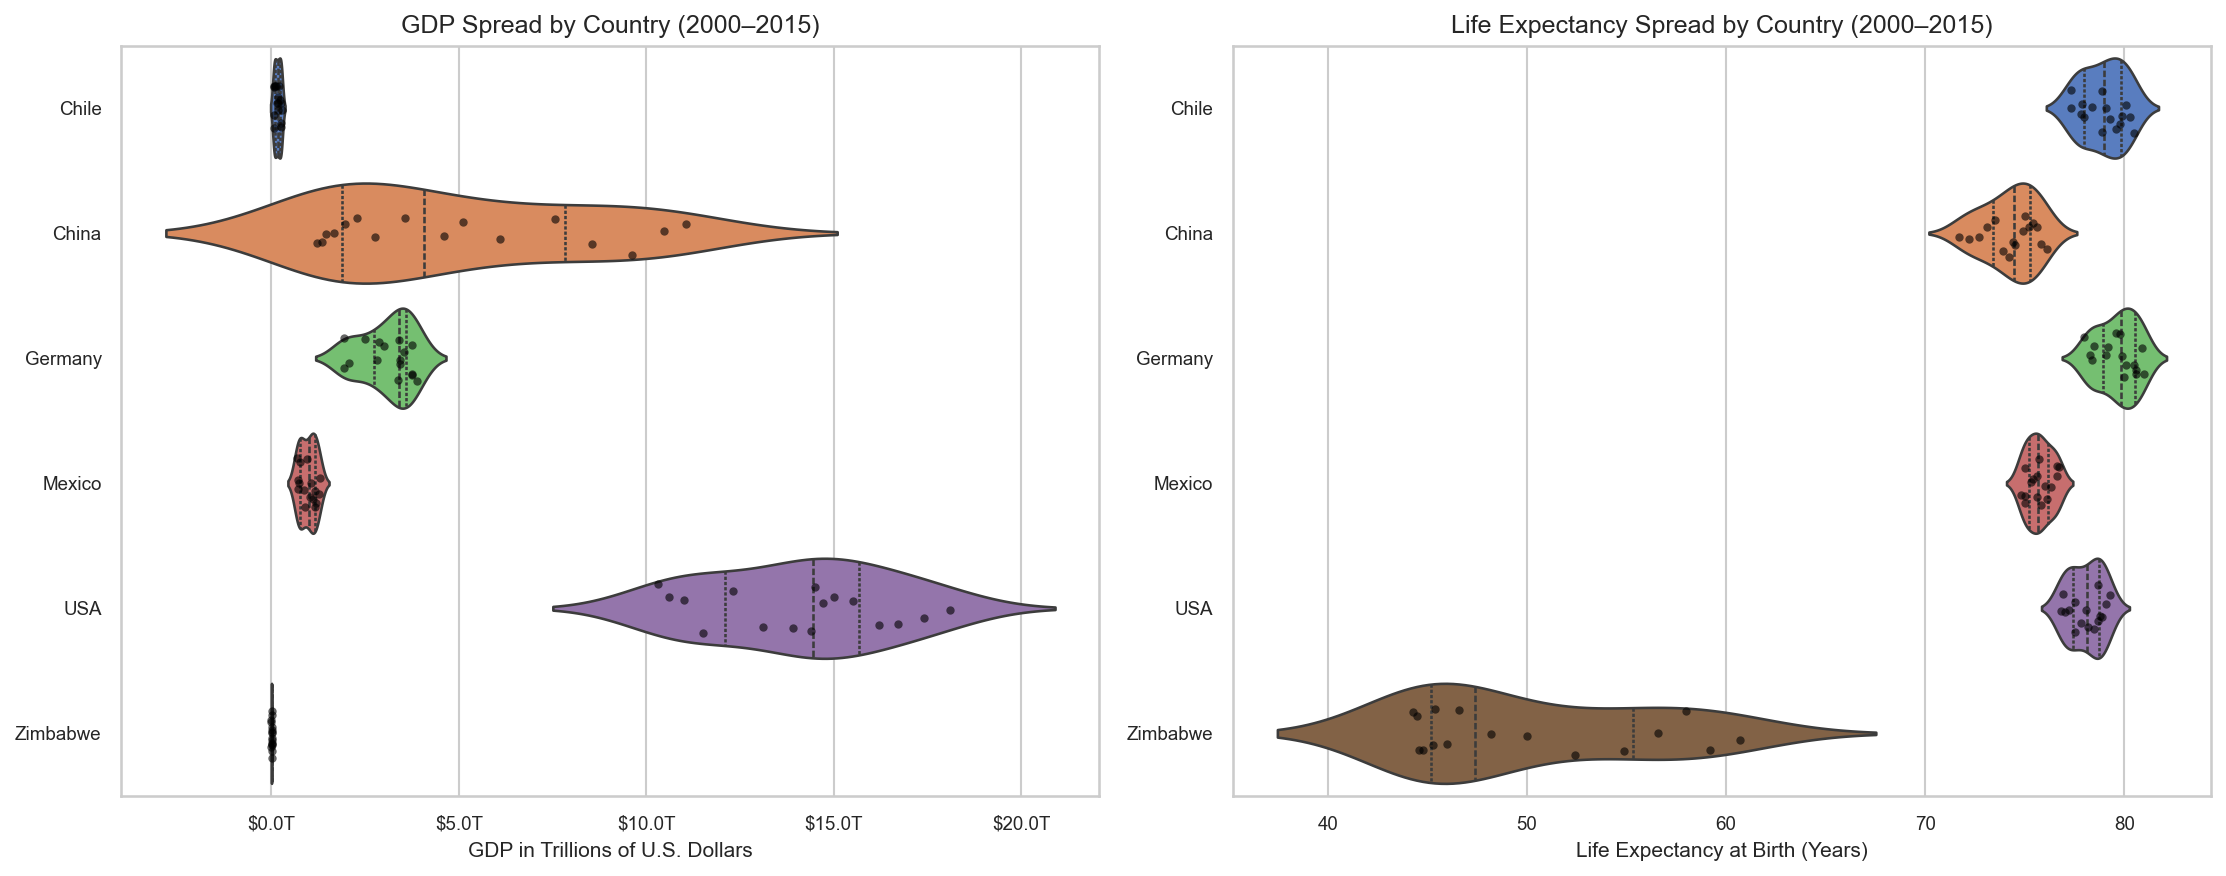

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# GDP Violin & Strip Plot
sns.violinplot(data=df, x="GDP_Trillions", y="Country_Short", inner="quartile", palette="muted", hue="Country_Short", legend=False, ax=axes[0])
sns.stripplot(data=df, x="GDP_Trillions", y="Country_Short", color="black", size=4, alpha=0.6, jitter=0.2, ax=axes[0])
axes[0].set_title("GDP Spread by Country (2000–2015)")
axes[0].set_xlabel("GDP in Trillions of U.S. Dollars")
axes[0].set_ylabel("")
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.1f}T"))

# Life Expectancy Violin & Strip Plot
sns.violinplot(data=df, x="LEABY", y="Country_Short", inner="quartile", palette="muted", hue="Country_Short", legend=False, ax=axes[1])
sns.stripplot(data=df, x="LEABY", y="Country_Short", color="black", size=4, alpha=0.6, jitter=0.2, ax=axes[1])
axes[1].set_title("Life Expectancy Spread by Country (2000–2015)")
axes[1].set_xlabel("Life Expectancy at Birth (Years)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


* **China** exhibits a widely stretched violin for GDP, illustrating its historic economic boom.
* **Zimbabwe** exhibits a widely stretched violin for life expectancy (ranging from under 45 to over 60 years), while its GDP remained compact at the low end.


## 7. Longitudinal Trends Over Time (2000–2015)
How did GDP and longevity evolve year by year?


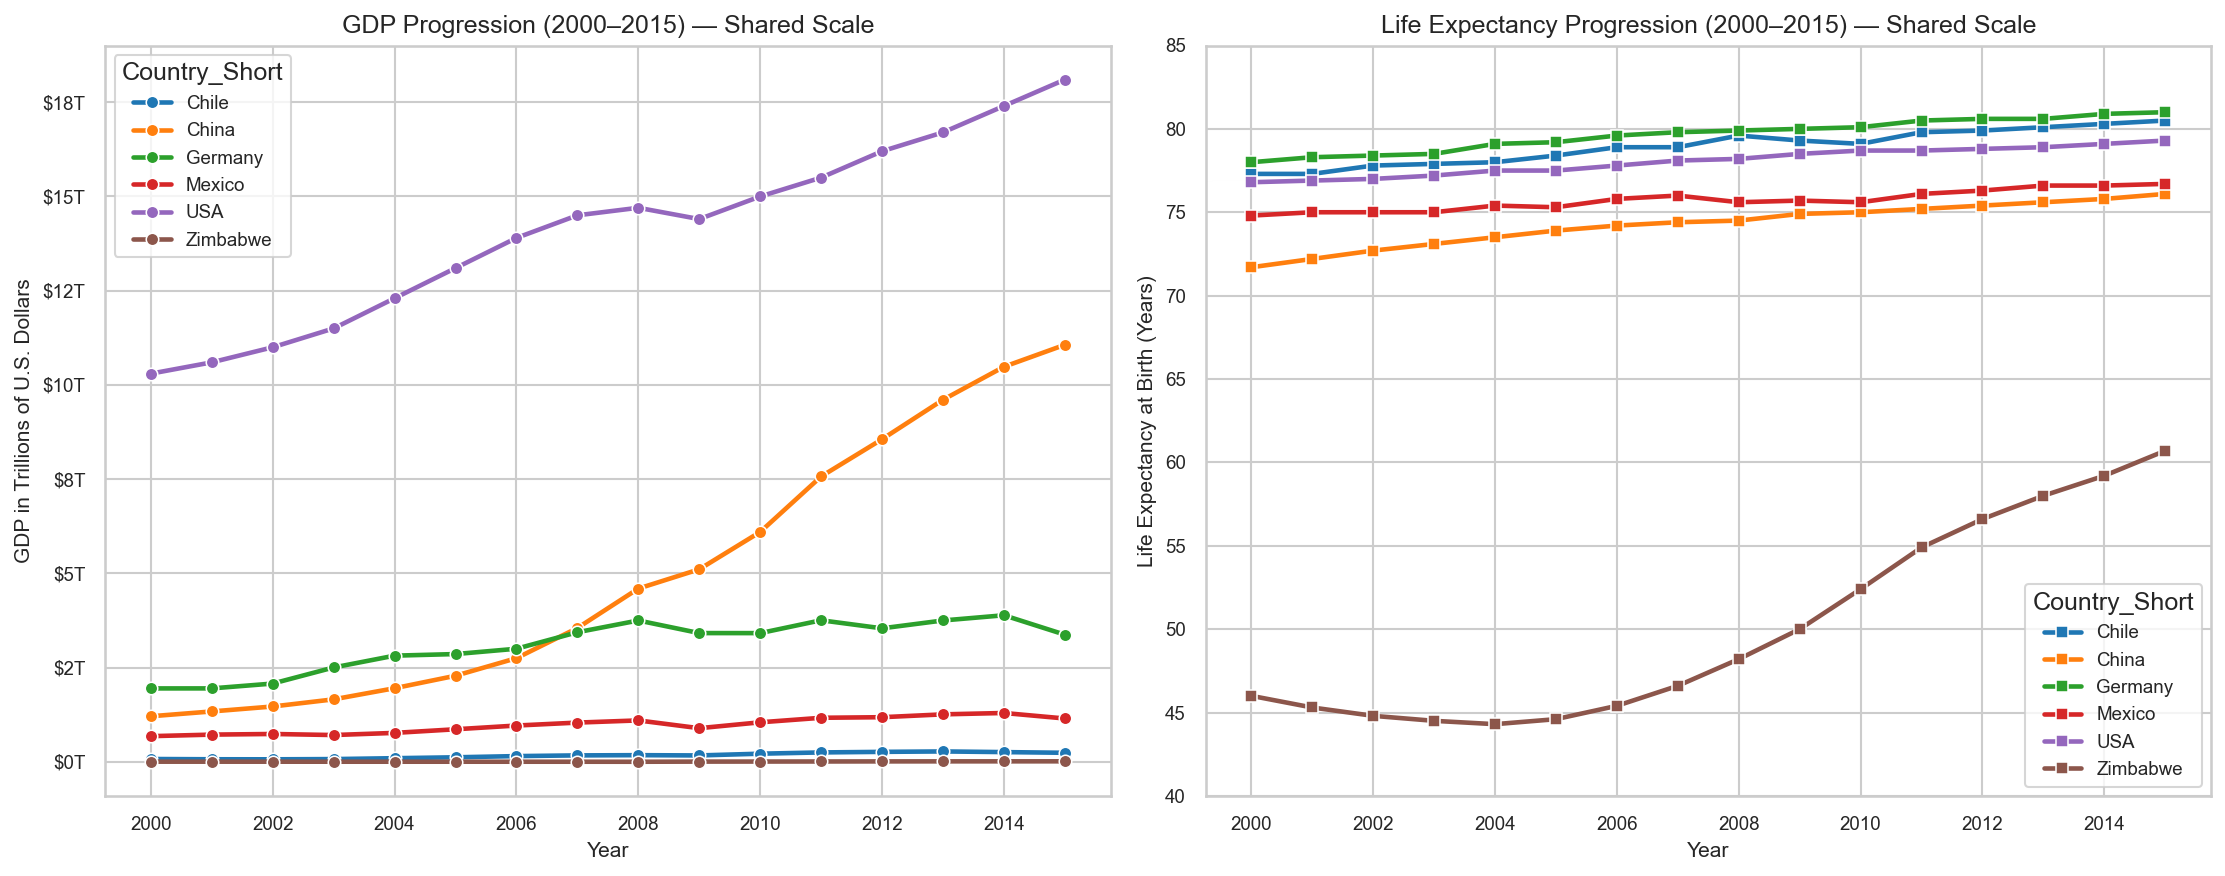

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
palette = sns.color_palette("tab10", n_colors=df["Country_Short"].nunique())

sns.lineplot(data=df, x="Year", y="GDP_Trillions", hue="Country_Short", palette=palette, marker="o", linewidth=2.2, ax=axes[0])
axes[0].set_title("GDP Progression (2000–2015) — Shared Scale")
axes[0].set_ylabel("GDP in Trillions of U.S. Dollars")
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.0f}T"))

sns.lineplot(data=df, x="Year", y="LEABY", hue="Country_Short", palette=palette, marker="s", linewidth=2.2, ax=axes[1])
axes[1].set_title("Life Expectancy Progression (2000–2015) — Shared Scale")
axes[1].set_ylabel("Life Expectancy at Birth (Years)")
axes[1].set_ylim(40, 85)

plt.tight_layout()
plt.show()


### Independent Scales: Faceted Grid Analysis
Because the US and China dominate the absolute GDP axis, changes in smaller economies (Chile, Mexico, Zimbabwe) are flattened on a shared scale. Faceting with `sharey=False` allows each country's individual trajectory to be examined clearly.


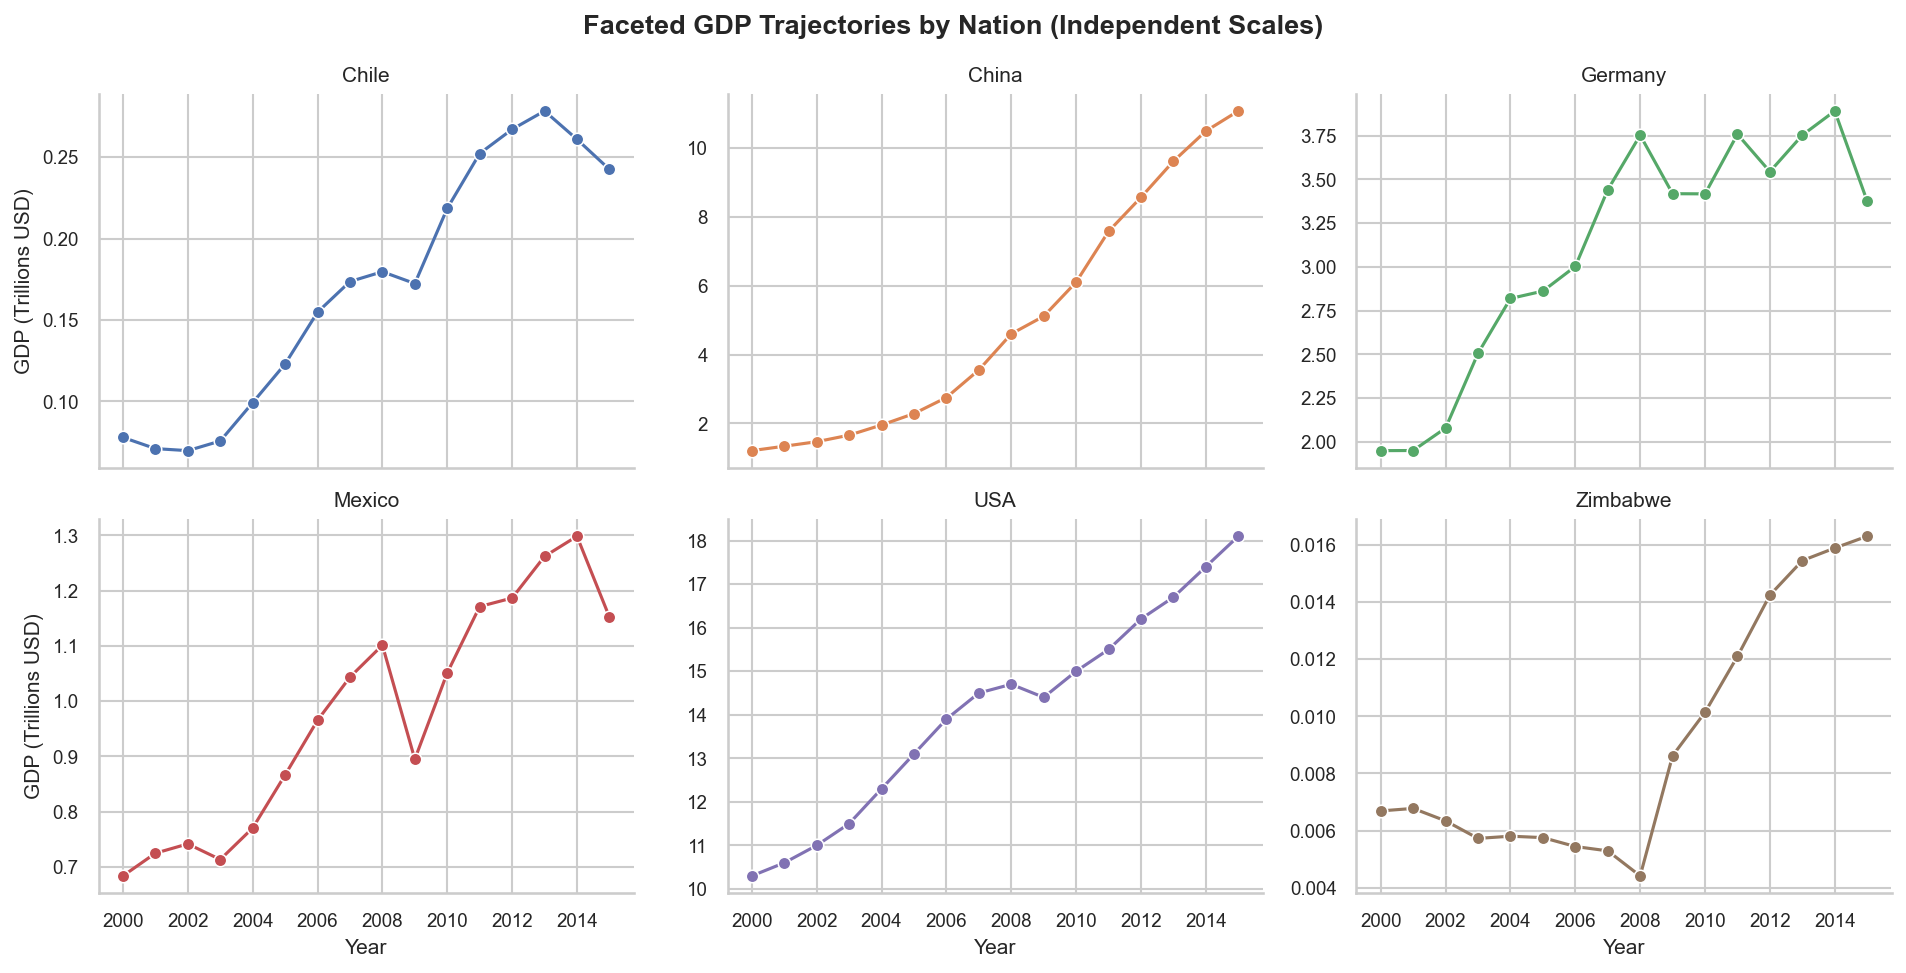

In [9]:
# Faceted GDP Trajectories
grid_gdp = sns.FacetGrid(df, col="Country_Short", col_wrap=3, hue="Country_Short", sharey=False, height=3.3, aspect=1.3)
grid_gdp.map(sns.lineplot, "Year", "GDP_Trillions", marker="o")
grid_gdp.set_axis_labels("Year", "GDP (Trillions USD)")
grid_gdp.set_titles(col_template="{col_name}")
grid_gdp.fig.subplots_adjust(top=0.9)
grid_gdp.fig.suptitle("Faceted GDP Trajectories by Nation (Independent Scales)", fontsize=13, fontweight="bold")
plt.show()


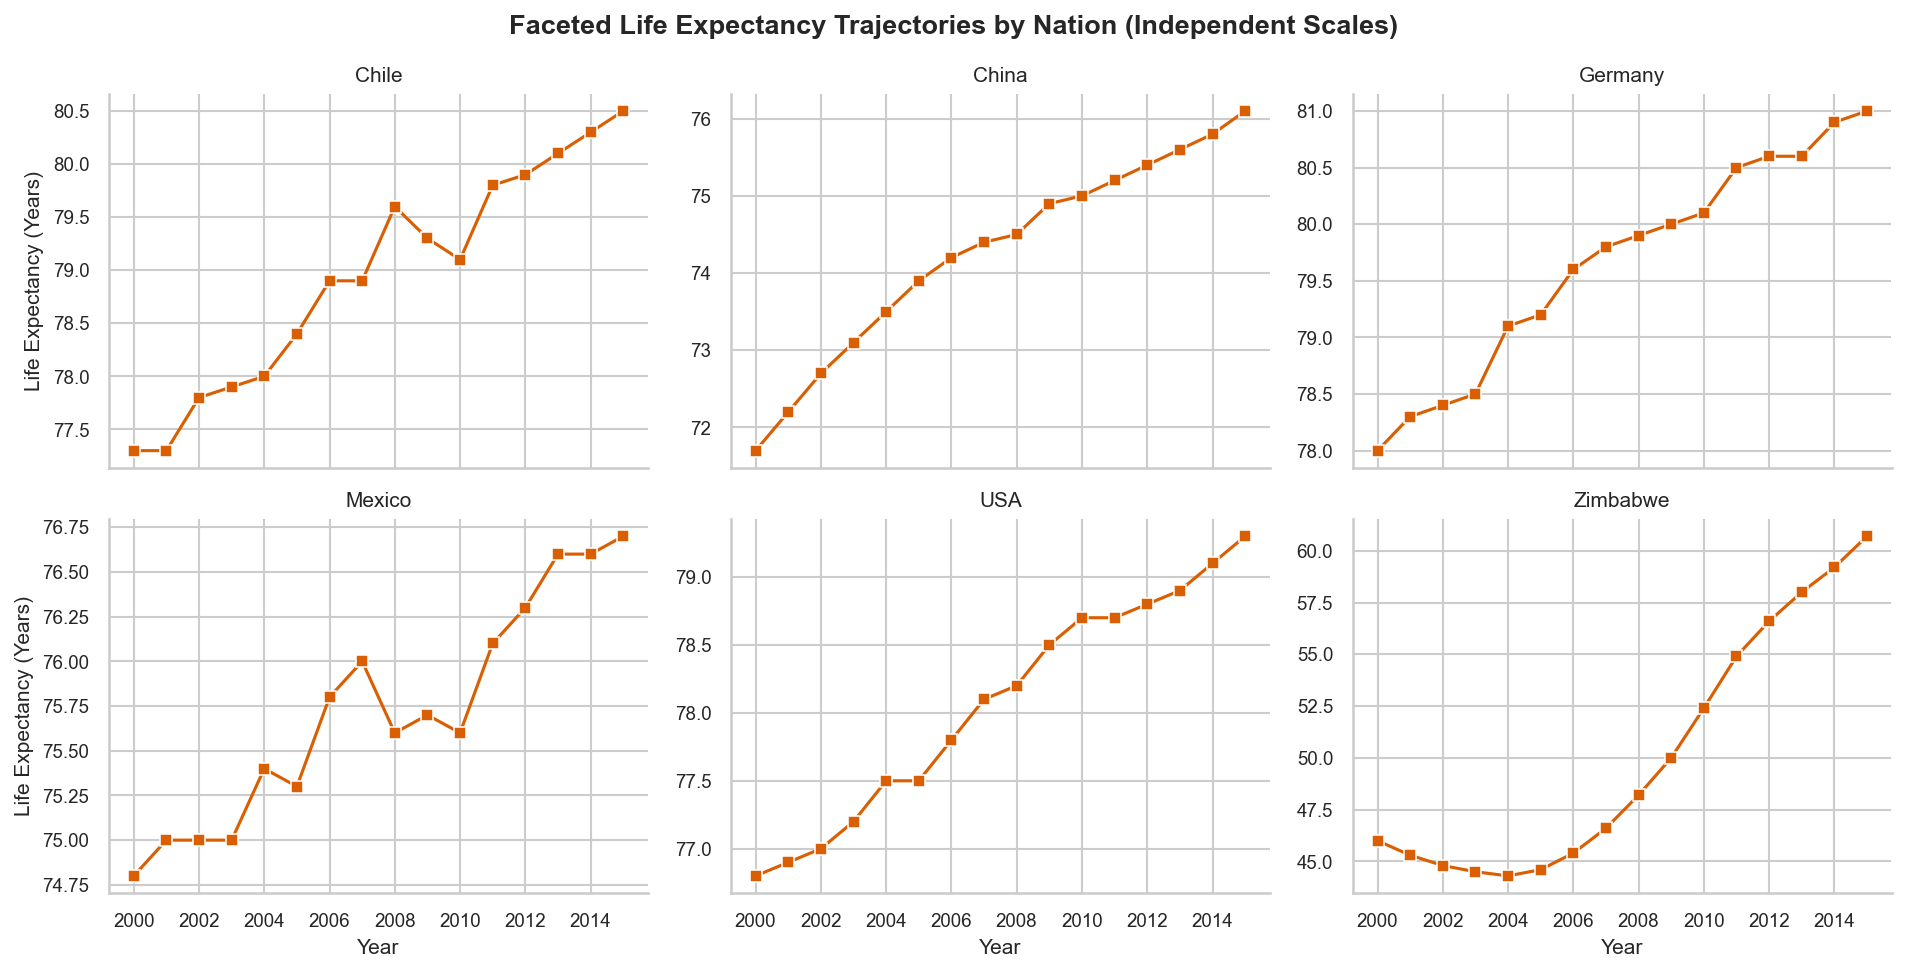

In [10]:
# Faceted Life Expectancy Trajectories
grid_le = sns.FacetGrid(df, col="Country_Short", col_wrap=3, hue="Country_Short", sharey=False, height=3.3, aspect=1.3)
grid_le.map(sns.lineplot, "Year", "LEABY", marker="s", color="#d95f02")
grid_le.set_axis_labels("Year", "Life Expectancy (Years)")
grid_le.set_titles(col_template="{col_name}")
grid_le.fig.subplots_adjust(top=0.9)
grid_le.fig.suptitle("Faceted Life Expectancy Trajectories by Nation (Independent Scales)", fontsize=13, fontweight="bold")
plt.show()


### Key Insights from Time Series
1. **Universal Growth:** Every single country experienced growth in both GDP and life expectancy between 2000 and 2015.
2. **Zimbabwe's Dramatic Turnaround:** Zimbabwe hit a low of 44.3 years in 2004, followed by a steep increase to 60.7 years by 2015 (+16.4 years gain!).
3. **China's Economic Miracle:** China's GDP skyrocketed from $1.21 Trillion in 2000 to over $11.06 Trillion in 2015 (+813% total growth, CAGR of 15.9%).
4. **Resilience to Shocks:** The 2008 global financial crisis produced a visible dip in Mexico's and Germany's GDP, but life expectancy showed remarkable resilience with zero downturn.


## 8. Statistical Growth Metrics (CAGR & Longevity Delta)
Let's quantify exact annualized growth rates (CAGR) and total longevity gains for each nation.


In [11]:
stats_records = []
for country, grp in df.groupby("Country"):
    g_sorted = grp.sort_values("Year")
    gdp_0 = g_sorted["GDP"].iloc[0]
    gdp_1 = g_sorted["GDP"].iloc[-1]
    le_0 = g_sorted["LEABY"].iloc[0]
    le_1 = g_sorted["LEABY"].iloc[-1]
    le_min = g_sorted["LEABY"].min()
    years = g_sorted["Year"].iloc[-1] - g_sorted["Year"].iloc[0]
    
    cagr = ((gdp_1 / gdp_0) ** (1 / years) - 1) * 100
    r_val = grp["GDP"].corr(grp["LEABY"])
    
    stats_records.append({
        "Country": country,
        "LE (2000)": f"{le_0:.1f}",
        "LE (2015)": f"{le_1:.1f}",
        "LE Gain": f"+{le_1 - le_0:.1f}y",
        "LE Min": f"{le_min:.1f}",
        "GDP 2000": f"${gdp_0 / 1e9:,.1f}B",
        "GDP 2015": f"${gdp_1 / 1e9:,.1f}B",
        "GDP Growth": f"+{((gdp_1 - gdp_0) / gdp_0) * 100:.1f}%",
        "GDP CAGR": f"{cagr:.1f}%",
        "Corr (r)": f"{r_val:.3f}",
    })

stats_df = pd.DataFrame(stats_records).sort_values(by="LE (2015)", ascending=False)
print(stats_df.to_string(index=False))


                 Country LE (2000) LE (2015) LE Gain LE Min   GDP 2000   GDP 2015 GDP Growth GDP CAGR Corr (r)
                 Germany      78.0      81.0   +3.0y   78.0  $1,950.0B  $3,375.6B     +73.1%     3.7%    0.933
                   Chile      77.3      80.5   +3.2y   77.3     $77.9B    $242.5B    +211.5%     7.9%    0.950
United States of America      76.8      79.3   +2.5y   76.8 $10,300.0B $18,100.0B     +75.7%     3.8%    0.982
                  Mexico      74.8      76.7   +1.9y   74.8    $683.6B  $1,152.3B     +68.5%     3.5%    0.932
                   China      71.7      76.1   +4.4y   71.7  $1,211.3B $11,064.7B    +813.4%    15.9%    0.909
                Zimbabwe      46.0      60.7  +14.7y   44.3      $6.7B     $16.3B    +143.7%     6.1%    0.966


## 9. Correlation Analysis & The Preston Curve
Now let's examine the central question: **How are GDP and life expectancy correlated?**

There is a striking paradox in the data:
* Within every individual country, the correlation between GDP and life expectancy is extremely high ($r \ge 0.91$).
* Yet, when pooling all data together in a naive linear model, the global Pearson correlation drops to just $r = 0.34$.
Why? Because wealth and longevity do not follow a simple linear relationship across nations. Instead, they follow the **Preston Curve**.


In [12]:
r_linear = df["GDP"].corr(df["LEABY"])
r_log = df["log_GDP"].corr(df["LEABY"])

print(f"Pooled Linear Pearson Correlation (GDP vs. LEABY):          r = {r_linear:.4f}")
print(f"Pooled Logarithmic Pearson Correlation (log10(GDP) vs. LEABY): r = {r_log:.4f}")


Pooled Linear Pearson Correlation (GDP vs. LEABY):          r = 0.3432
Pooled Logarithmic Pearson Correlation (log10(GDP) vs. LEABY): r = 0.7873


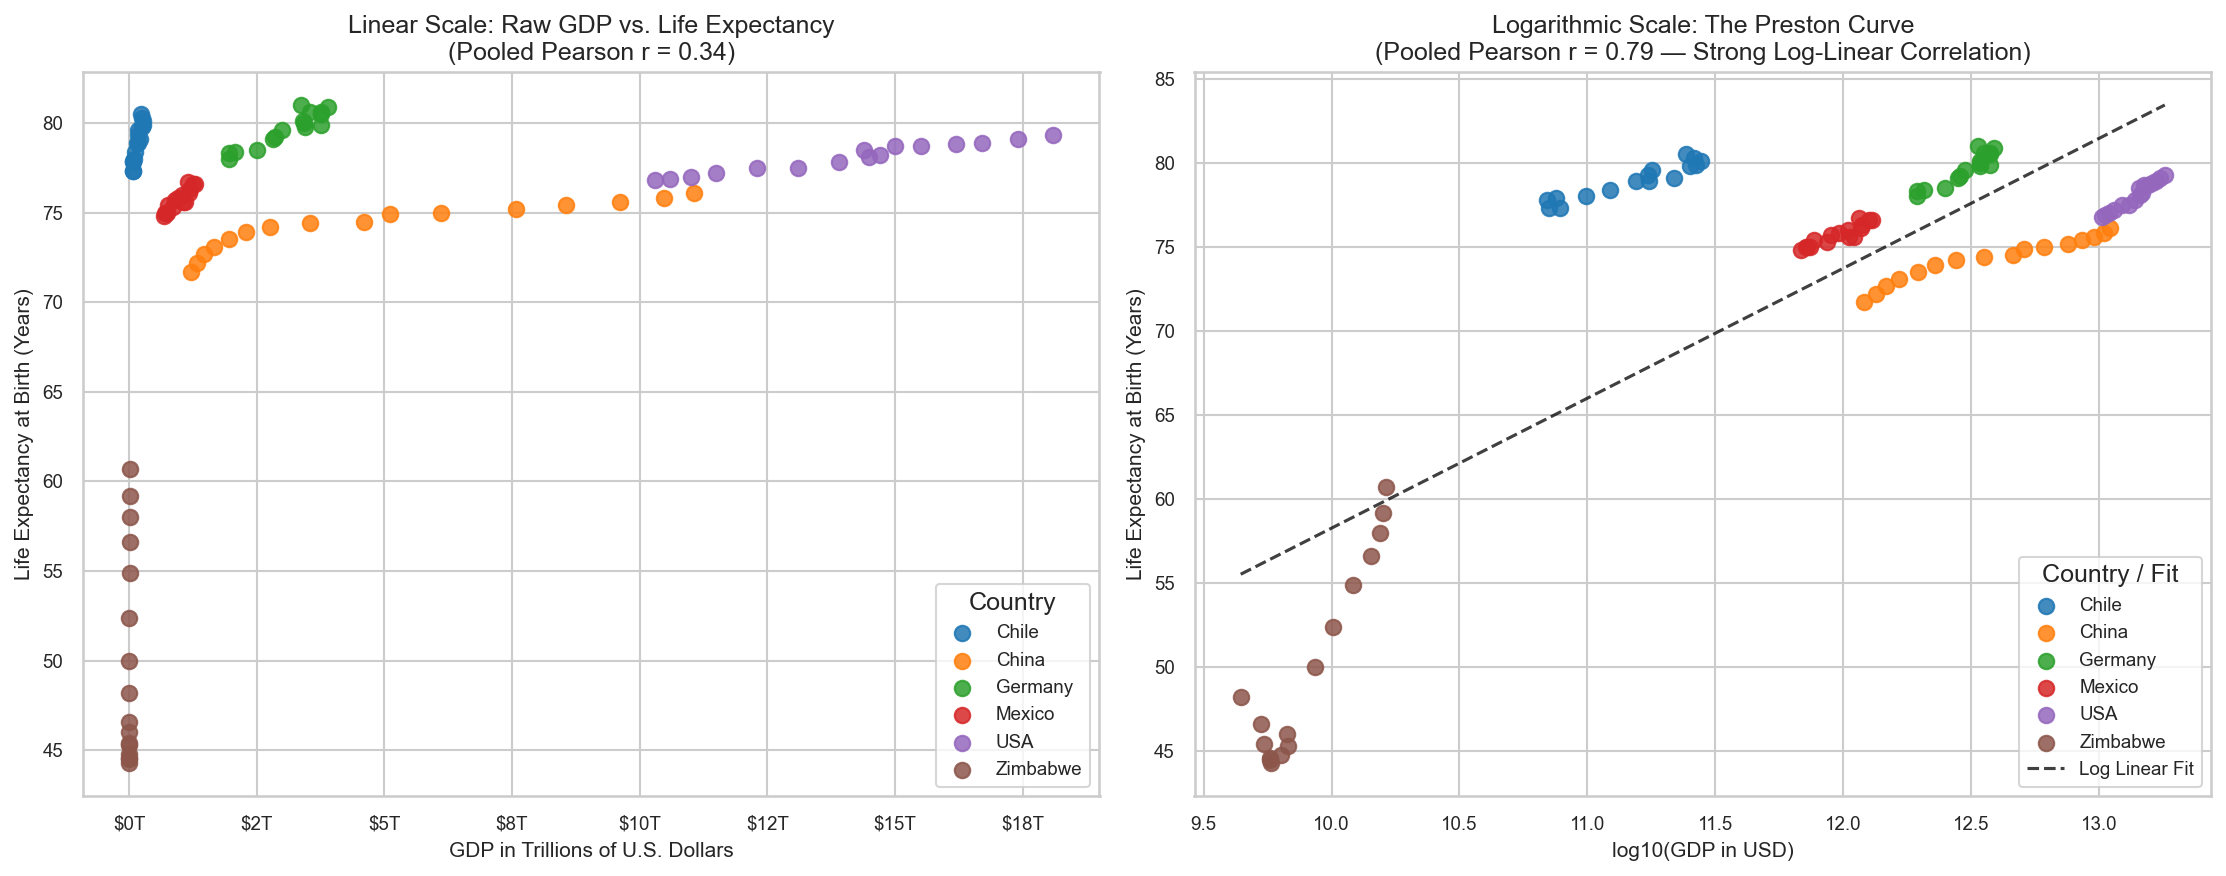

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

countries = df["Country_Short"].unique()
palette_dict = dict(zip(countries, sns.color_palette("tab10", len(countries))))

# 1. Linear Scale (Raw GDP)
for c in countries:
    sub = df[df["Country_Short"] == c]
    axes[0].scatter(sub["GDP_Trillions"], sub["LEABY"], label=c, color=palette_dict[c], s=55, alpha=0.85)

axes[0].set_title(f"Linear Scale: Raw GDP vs. Life Expectancy\n(Pooled Pearson r = {r_linear:.2f})")
axes[0].set_xlabel("GDP in Trillions of U.S. Dollars")
axes[0].set_ylabel("Life Expectancy at Birth (Years)")
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.0f}T"))
axes[0].legend(title="Country", loc="lower right")

# 2. Logarithmic Scale (The Preston Curve)
for c in countries:
    sub = df[df["Country_Short"] == c]
    axes[1].scatter(sub["log_GDP"], sub["LEABY"], label=c, color=palette_dict[c], s=55, alpha=0.85)

# Log Trendline
m, b = np.polyfit(df["log_GDP"], df["LEABY"], 1)
x_line = np.linspace(df["log_GDP"].min(), df["log_GDP"].max(), 100)
axes[1].plot(x_line, m * x_line + b, color="black", linestyle="--", alpha=0.75, label="Log Linear Fit")

axes[1].set_title(f"Logarithmic Scale: The Preston Curve\n(Pooled Pearson r = {r_log:.2f} — Strong Log-Linear Correlation)")
axes[1].set_xlabel("log10(GDP in USD)")
axes[1].set_ylabel("Life Expectancy at Birth (Years)")
axes[1].legend(title="Country / Fit", loc="lower right")

plt.tight_layout()
plt.show()


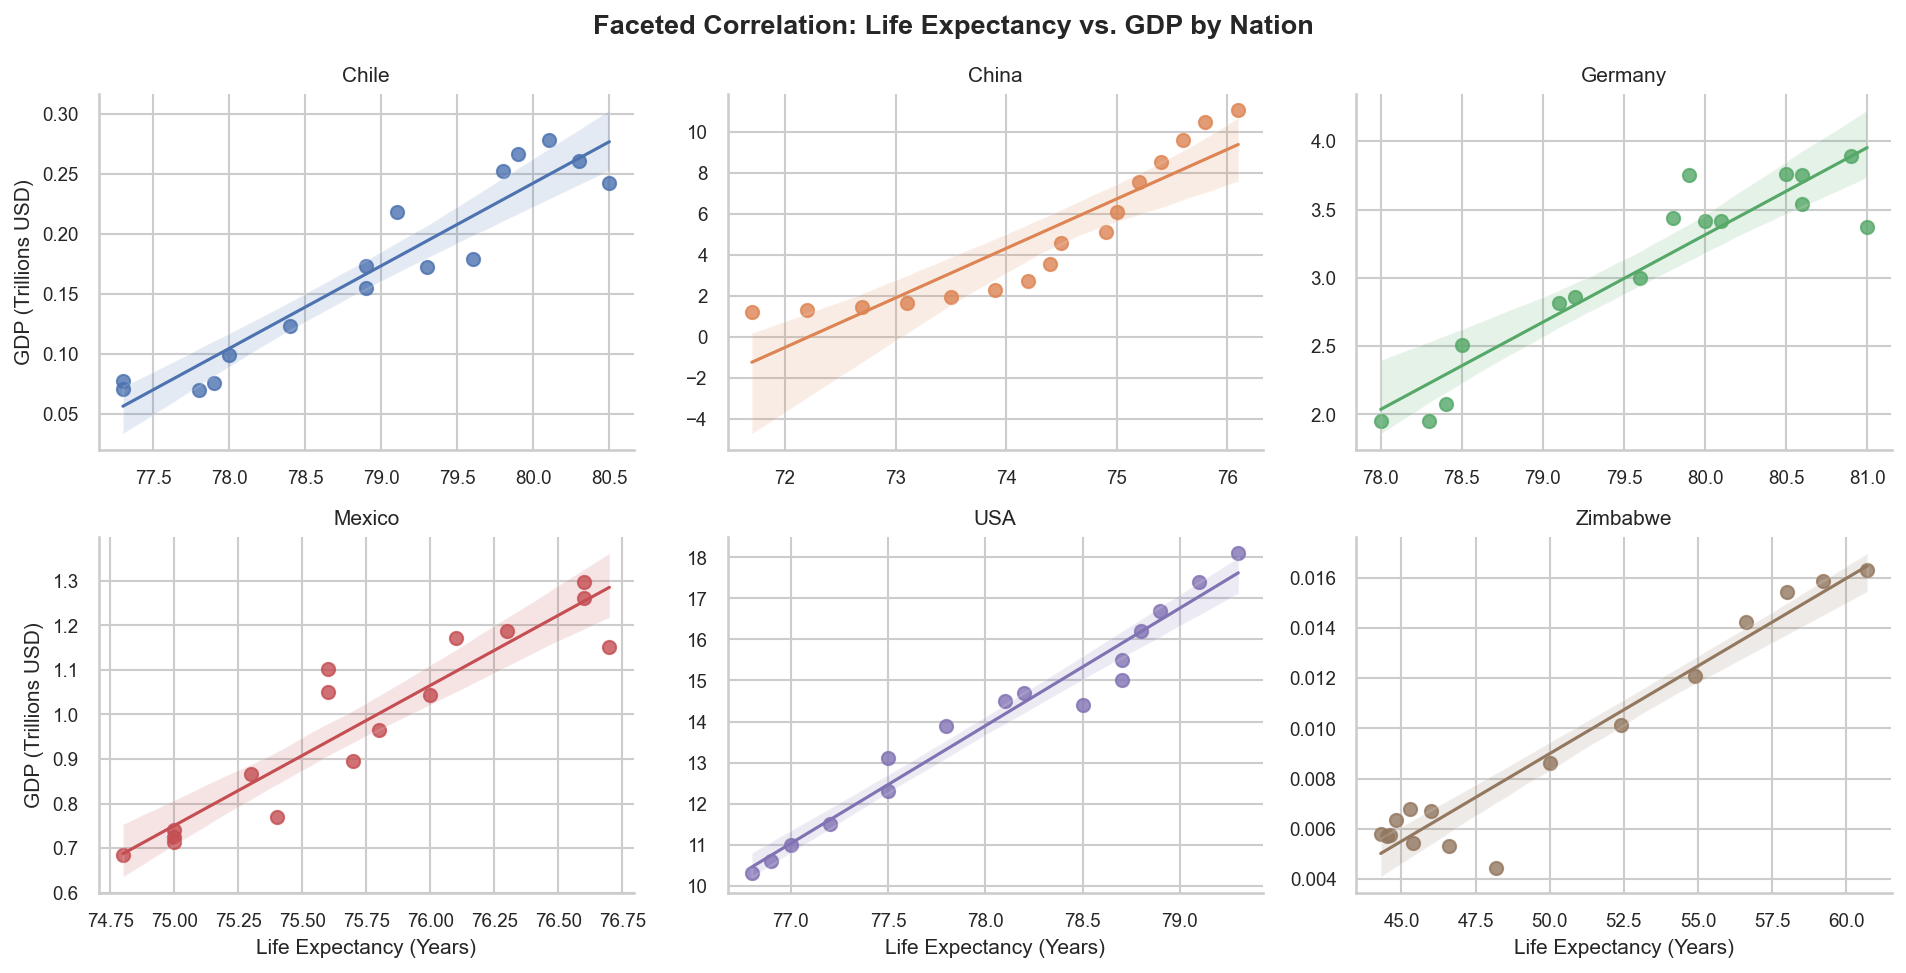

In [14]:
# Faceted Scatter Plots with Local Trendlines
grid_scatter = sns.FacetGrid(df, col="Country_Short", col_wrap=3, hue="Country_Short", sharey=False, sharex=False, height=3.3, aspect=1.3)
grid_scatter.map(sns.regplot, "LEABY", "GDP_Trillions", scatter_kws={"s": 40, "alpha": 0.8}, line_kws={"linewidth": 1.5})
grid_scatter.set_axis_labels("Life Expectancy (Years)", "GDP (Trillions USD)")
grid_scatter.set_titles(col_template="{col_name}")
grid_scatter.fig.subplots_adjust(top=0.9)
grid_scatter.fig.suptitle("Faceted Correlation: Life Expectancy vs. GDP by Nation", fontsize=13, fontweight="bold")
plt.show()


### Theoretical Interpretation: Samuel Preston's Hypothesis
In 1975, demographer Samuel H. Preston published the seminal paper showing that the relationship between economic output and life expectancy is concave:
1. **Low-Income Threshold:** In low-GDP nations (e.g., Zimbabwe), even modest increases in economic capacity yield substantial jumps in life expectancy due to basic sanitation, immunization, maternal care, and food security.
2. **Diminishing Marginal Health Returns:** In high-GDP nations (Germany, USA), adding trillions of dollars in economic output yields only fractional increases in lifespan, as longevity becomes constrained by biological limits, chronic aging diseases, and lifestyle factors.
3. **Logarithmic Concordance:** When taking $\log_{10}(\text{GDP})$, the relationship becomes strongly linear ($r = 0.79$).


## 10. Conclusions & Key Findings

1. **Has life expectancy increased over time in the six nations?**
   * **Yes.** All six countries saw clear increases in life expectancy from 2000 to 2015.
   * **Zimbabwe** achieved the most astonishing transformation, increasing by **+14.7 years** (and +16.4 years from its 2004 nadir).
2. **Has GDP increased over time in the six nations?**
   * **Yes.** All six economies expanded. **China** recorded an extraordinary **+813% growth** ($1.2T to $11.1T, CAGR 15.9%).
3. **Is there a correlation between GDP and life expectancy?**
   * **Within countries:** Exceptionally strong ($r = 0.91$ to $0.98$). Every nation lived longer as its economy grew.
   * **Across countries:** A simple linear model gives $r = 0.34$, while a logarithmic model gives $r = 0.79$, confirming the Preston Curve.
4. **What is the average life expectancy in these nations?**
   * Western and emerging nations clustered closely: Germany (79.7y), Chile (78.9y), USA (78.1y), Mexico (75.7y), and China (74.3y). Zimbabwe averaged 50.1 years over the period due to the early-2000s health crisis.


## 11. Real-World Context & Further Research
* **Zimbabwe's Recovery Post-2004:** The dramatic resurgence in Zimbabwean life expectancy after 2004 coincides with the widespread rollout of international antiretroviral therapy (ART) programs for HIV/AIDS, expanded malaria prevention, and stabilization of healthcare access.
* **China's Expansion:** Following China's entry into the WTO in December 2001, foreign direct investment, manufacturing exports, and domestic infrastructure spending surged, translating to both double-digit GDP gains and modernizing urban healthcare access.
* **Next Steps:** Future research could integrate **GDP per capita** (PPP-adjusted) and healthcare expenditure as a % of GDP to control for population scale disparities (e.g. comparing China's 1.4B population to Chile's 18M).
